In [6]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/resized_yellow (179).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/rotated_yellow (237).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/resized_yellow (407).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/resized_yellow (147).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/resized_yellow (70).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/rotated_yellow (430).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/zoomed_yellow (251).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Yellow/flipped_vert_yellow (221).jpeg
/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Su

In [7]:
dataset_path = "/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs"

In [8]:
import os
print(os.listdir(dataset_path))

['Yellow', 'Mosaic', 'BacterialBlights', 'Healthy', 'RedRot', 'Rust']


In [9]:
import os
import shutil
import random
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models
import matplotlib.pyplot as plt

In [10]:
base_dir = "/kaggle/working/dataset"

train_dir = os.path.join(base_dir, "train")
test_dir = os.path.join(base_dir, "test")

os.makedirs(train_dir, exist_ok=True)
os.makedirs(test_dir, exist_ok=True)

split_ratio = 0.8

for class_name in os.listdir(dataset_path):
    class_path = os.path.join(dataset_path, class_name)

    if os.path.isdir(class_path):
        images = os.listdir(class_path)
        random.shuffle(images)

        split_index = int(len(images) * split_ratio)

        train_images = images[:split_index]
        test_images = images[split_index:]

        os.makedirs(os.path.join(train_dir, class_name), exist_ok=True)
        os.makedirs(os.path.join(test_dir, class_name), exist_ok=True)

        for img in train_images:
            shutil.copy(os.path.join(class_path, img),
                        os.path.join(train_dir, class_name, img))

        for img in test_images:
            shutil.copy(os.path.join(class_path, img),
                        os.path.join(test_dir, class_name, img))

print("Dataset Split Completed ✅")

Dataset Split Completed ✅


In [11]:
print("Train:", os.listdir(train_dir))
print("Test:", os.listdir(test_dir))

Train: ['RedRot', 'Rust', 'Healthy', 'Yellow', 'BacterialBlights', 'Mosaic']
Test: ['RedRot', 'Rust', 'Healthy', 'Yellow', 'BacterialBlights', 'Mosaic']


In [12]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

img_size = (224, 224)
batch_size = 32

train_gen = ImageDataGenerator(rescale=1./255)
val_gen = ImageDataGenerator(rescale=1./255)

train_data = train_gen.flow_from_directory(
    train_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

val_data = val_gen.flow_from_directory(
    test_dir,
    target_size=img_size,
    batch_size=batch_size,
    class_mode='categorical'
)

Found 19132 images belonging to 6 classes.
Found 7180 images belonging to 6 classes.


In [13]:
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras import layers, models

base_model = MobileNetV2(
    input_shape=(224, 224, 3),
    include_top=False,
    weights='imagenet'
)

base_model.trainable = False

I0000 00:00:1778272498.798222     197 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13757 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1778272498.803392     197 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13757 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


In [14]:
model = models.Sequential([
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.5),
    layers.Dense(train_data.num_classes, activation='softmax')
])

In [15]:
model.compile(
    optimizer='adam',
    loss='categorical_crossentropy',
    metrics=['accuracy']
)
model.summary

<bound method Model.summary of <Sequential name=sequential, built=True>>

In [16]:
history = model.fit(
    train_data,
    validation_data=val_data,
    epochs=20
)

/usr/local/lib/python3.12/dist-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


Epoch 1/20


I0000 00:00:1778272505.368347     258 service.cc:152] XLA service 0x792ac8112250 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1778272505.368386     258 service.cc:160]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1778272505.368392     258 service.cc:160]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1778272506.339687     258 cuda_dnn.cc:529] Loaded cuDNN version 91002
2026-05-08 20:35:14.126149: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-08 20:35:14.263406: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
I0000 00:00:1778272516.512567     258 device_co

466/598 ━━━━━━━━━━━━━━━━━━━━ 12s 97ms/step - accuracy: 0.6136 - loss: 1.0477

2026-05-08 20:36:10.540234: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-08 20:36:10.677113: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


598/598 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step - accuracy: 0.6334 - loss: 0.9923

2026-05-08 20:36:58.130825: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-08 20:36:58.267938: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


598/598 ━━━━━━━━━━━━━━━━━━━━ 120s 173ms/step - accuracy: 0.6335 - loss: 0.9920 - val_accuracy: 0.8375 - val_loss: 0.4603
Epoch 2/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 76s 127ms/step - accuracy: 0.7983 - loss: 0.5548 - val_accuracy: 0.8635 - val_loss: 0.3780
Epoch 3/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 80s 134ms/step - accuracy: 0.8263 - loss: 0.4683 - val_accuracy: 0.8781 - val_loss: 0.3424
Epoch 4/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 76s 128ms/step - accuracy: 0.8357 - loss: 0.4399 - val_accuracy: 0.8818 - val_loss: 0.3210
Epoch 5/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 76s 127ms/step - accuracy: 0.8473 - loss: 0.4016 - val_accuracy: 0.8958 - val_loss: 0.2882
Epoch 6/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 74s 124ms/step - accuracy: 0.8578 - loss: 0.3707 - val_accuracy: 0.9068 - val_loss: 0.2556
Epoch 7/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 77s 128ms/step - accuracy: 0.8715 - loss: 0.3432 - val_accuracy: 0.9159 - val_loss: 0.2383
Epoch 8/20
598/598 ━━━━━━━━━━━━━━━━━━━━ 77s 129ms/step - accuracy: 0.8755 - loss: 0.3298 - va

In [17]:
model.save("/kaggle/working/model.h5")
print("Model saved!")
# Training ke baad sahi path pe save karo


Model saved!


In [18]:
for folder in os.listdir(dataset_path):
    path = os.path.join(dataset_path, folder)
    print(folder, len(os.listdir(path)))

Yellow 3030
Mosaic 2772
BacterialBlights 4800
Healthy 3132
RedRot 3108
Rust 3084


In [19]:
base_model = model.get_layer("mobilenetv2_1.00_224")

In [20]:
for layer in base_model.layers[::-1]:
    if "conv" in layer.name:
        print(layer.name)
        last_conv_layer_name = layer.name
        break

expanded_conv_project_BN


In [21]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt

In [22]:
def make_gradcam_heatmap(img_array, model, base_model, last_conv_layer_name):

    grad_model = tf.keras.models.Model(
        inputs=model.input,
        outputs=[
            base_model.get_layer(last_conv_layer_name).output,
            model.output
        ]
    )

    with tf.GradientTape() as tape:
        conv_outputs, predictions = grad_model(img_array)
        class_idx = tf.argmax(predictions[0])
        loss = predictions[:, class_idx]

    grads = tape.gradient(loss, conv_outputs)

    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_outputs = conv_outputs[0]

    heatmap = tf.reduce_sum(conv_outputs * pooled_grads, axis=-1)

    heatmap = tf.maximum(heatmap, 0) / tf.reduce_max(heatmap)
    return heatmap.numpy()

In [23]:
img_path = "/kaggle/input/datasets/akilesh253/sugarcane-plant-diseases-dataset/Sugarcane_leafs/Healthy/cropped_healthy (1).jpeg"

In [24]:
import cv2
import matplotlib.pyplot as plt

img = cv2.imread(img_path)

if img is None:
    print("❌ Image not loaded (path wrong)")
else:
    print("✅ Image loaded")

✅ Image loaded


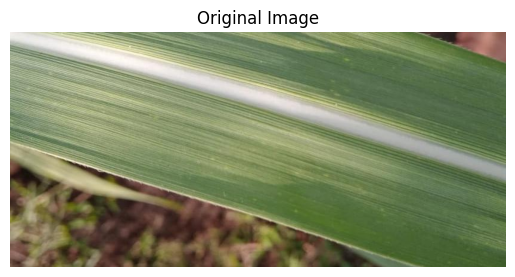

In [25]:
plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
plt.title("Original Image")
plt.axis('off')
plt.show()

In [26]:
img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
img_array = tf.keras.preprocessing.image.img_to_array(img)
img_array = np.expand_dims(img_array, axis=0) / 255.0

In [27]:
model.predict(img_array)

2026-05-08 21:01:22.931176: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.
2026-05-08 21:01:23.074332: E external/local_xla/xla/stream_executor/cuda/cuda_timer.cc:86] Delay kernel timed out: measured time has sub-optimal accuracy. There may be a missing warmup execution, please investigate in Nsight Systems.


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step


array([[4.6573632e-07, 9.6467781e-01, 1.3631058e-02, 5.7681516e-04,
        2.0688912e-02, 4.2490027e-04]], dtype=float32)

In [28]:
preds = model.predict(img_array)

class_idx = np.argmax(preds[0])
confidence = np.max(preds[0])

class_names = list(train_data.class_indices.keys())

print("Predicted Class:", class_names[class_idx])
print("Confidence:", round(confidence * 100, 2), "%")

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
Predicted Class: Healthy
Confidence: 96.47 %


In [29]:
model.save("/kaggle/working/sugarcane_model.keras")
print("✅ Saved!")

✅ Saved!


In [30]:
model = tf.keras.models.load_model("/kaggle/working/sugarcane_model.keras")

/usr/local/lib/python3.12/dist-packages/keras/src/saving/saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'rmsprop', because it has 6 variables whereas the saved optimizer has 10 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [31]:

print("Model ready:", model.input_shape)
print("Classes:", list(train_data.class_indices.keys()))

Model ready: (None, 224, 224, 3)
Classes: ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']


In [32]:

dummy = np.zeros((1, 224, 224, 3))
model(dummy)
print("✅ Model ready!")

✅ Model ready!


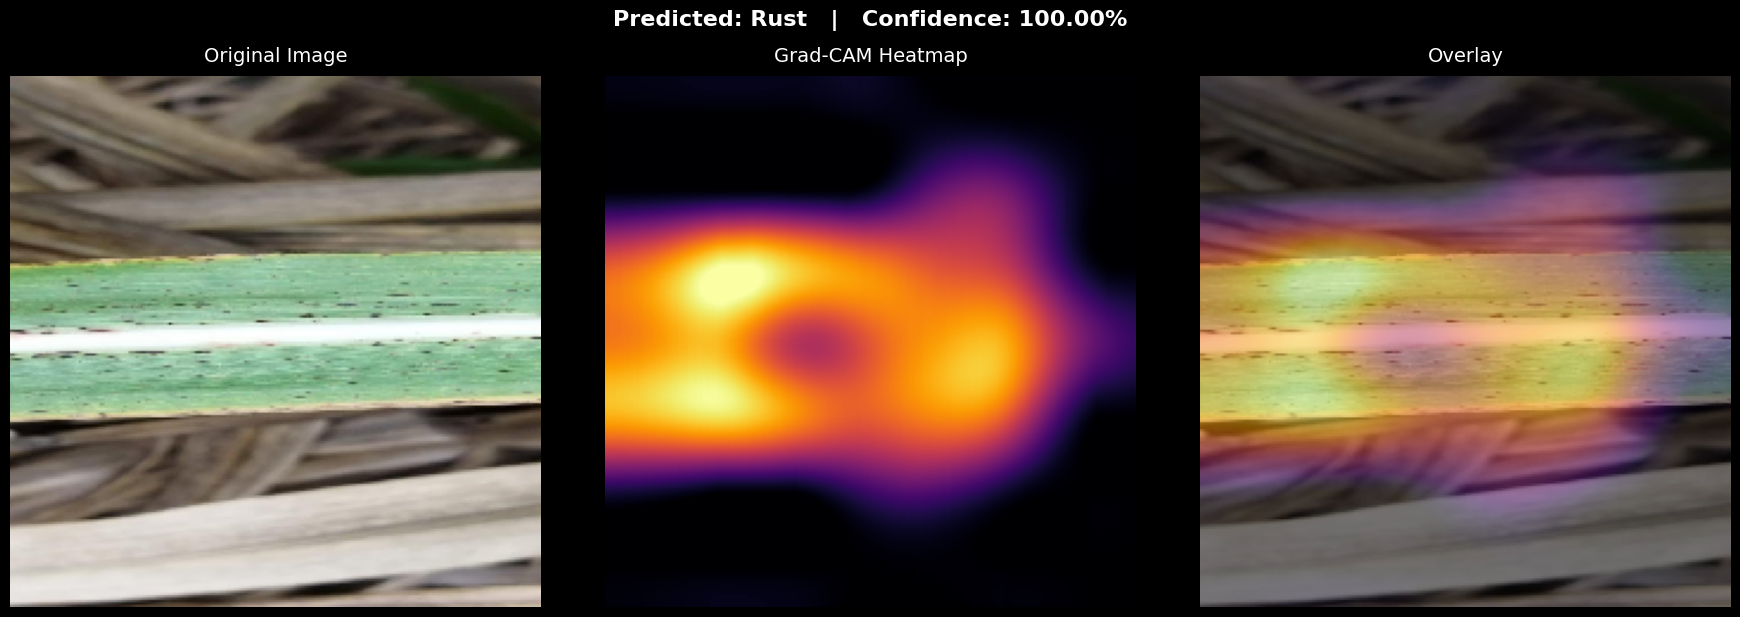

✅ Predicted: Rust — 100.00%


In [41]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from PIL import Image

def make_gradcam_heatmap(img_array, model, pred_index=None):
    mobilenet = model.get_layer('mobilenetv2_1.00_224')
    with tf.GradientTape() as tape:
        img_tensor = tf.cast(img_array, tf.float32)
        tape.watch(img_tensor)
        conv_output = mobilenet(img_tensor)
        tape.watch(conv_output)
        x = model.get_layer('global_average_pooling2d')(conv_output)
        x = model.get_layer('dense')(x)
        x = model.get_layer('dropout')(x)
        predictions = model.get_layer('dense_1')(x)
        if pred_index is None:
            pred_index = tf.argmax(predictions[0])
        class_channel = predictions[:, pred_index]
    grads = tape.gradient(class_channel, conv_output)
    pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
    conv_output = conv_output[0]
    heatmap = conv_output @ pooled_grads[..., tf.newaxis]
    heatmap = tf.squeeze(heatmap)
    heatmap = tf.maximum(heatmap, 0) / (tf.math.reduce_max(heatmap) + 1e-8)
    return heatmap.numpy(), predictions.numpy()


def display_gradcam(img_path, model, class_names):
    img = tf.keras.preprocessing.image.load_img(img_path, target_size=(224, 224))
    img_array = tf.keras.preprocessing.image.img_to_array(img)
    img_array_expanded = np.expand_dims(img_array, axis=0) / 255.0
    heatmap, preds = make_gradcam_heatmap(img_array_expanded, model)
    pred_index = np.argmax(preds[0])
    confidence = np.max(preds[0]) * 100
    predicted_class = class_names[pred_index]
    heatmap_img = Image.fromarray(np.uint8(255 * heatmap)).resize((224, 224), Image.LANCZOS)
    heatmap_smooth = np.array(heatmap_img) / 255.0
    heatmap_colored = np.uint8(cm.inferno(heatmap_smooth)[:, :, :3] * 255)
    original = np.uint8(img_array)
    overlay = np.uint8(heatmap_colored * 0.5 + original * 0.5)
    fig, axes = plt.subplots(1, 3, figsize=(18, 6))
    fig.patch.set_facecolor('black')
    axes[0].imshow(original)
    axes[0].set_title("Original Image", fontsize=14, color='white', pad=10)
    axes[0].axis('off')
    axes[1].imshow(heatmap_smooth, cmap='inferno')
    axes[1].set_title("Grad-CAM Heatmap", fontsize=14, color='white', pad=10)
    axes[1].axis('off')
    axes[2].imshow(overlay)
    axes[2].set_title("Overlay", fontsize=14, color='white', pad=10)
    axes[2].axis('off')
    plt.suptitle(f"Predicted: {predicted_class}   |   Confidence: {confidence:.2f}%",
                 fontsize=16, fontweight='bold', color='white', y=1.02)
    plt.tight_layout()
    plt.show()
    print(f"✅ Predicted: {predicted_class} — {confidence:.2f}%")


class_names = ['BacterialBlights', 'Healthy', 'Mosaic', 'RedRot', 'Rust', 'Yellow']

img_path = "/kaggle/working/dataset/test/Rust/cropped_rust (119).jpeg"

display_gradcam(img_path, model, class_names)

In [35]:
model.save("/kaggle/working/sugarcane_model.keras")
print("✅ Saved!")

✅ Saved!


In [4]:
model.save("/kaggle/working/sugarcane_model.keras")
print("✅ Saved!")

✅ Saved!


In [8]:
import numpy as np
import tensorflow as tf
import cv2
import matplotlib.pyplot as plt
import json

model = tf.keras.models.load_model("/kaggle/input/datasets/saeedshaikh80380/sugarcane-model2/sugarcane_model (1).keras")
print("✅ Model loaded!")



✅ Model loaded!
